# StyleBot — Entrega 3: Q-Learning y Dyna-Q

**Responsable:** Luis Ángel Mendoza Gaytán
**Rol:** Simulación y aprendizaje por refuerzo
**Protocolo:** `datos/entrega3/protocolo_entrega3.json` (`entrega3-1.0`)
**Archivos de esta sección:** `src/entrega3/entorno_almacen.py`, `src/entrega3/agentes_rl.py`, `modelos/entrega3/q_table_qlearning.npz`, `modelos/entrega3/q_table_dynaq.npz`

**Objetivos**

1. Entrenar Q-Learning y Dyna-Q tabulares en el almacén `AlmacenStyleBot` (8×8, 1408 estados, 6 acciones).
2. Probar las dos configuraciones del protocolo (A y B) en ambos algoritmos y, en Dyna-Q, 10 y 30 pasos de planeación.
3. Elegir la mejor configuración de cada algoritmo **solo con episodios de validación** (semillas 500–549).
4. Evaluar las políticas elegidas en las semillas comunes 1000–1049, sin exploración ni actualización de la tabla Q, junto con el agente aleatorio.
5. Guardar las tablas Q y los resultados reproducibles que usan Ángel (evaluación) y Jacqueline (integración y demo).
6. Simular las 50 prendas percibidas por la CNN congelada (`semilla_demo = 2026`) y separar fallos de la CNN y de la política.

In [1]:
# Preparación: funciona en Google Colab y en una copia local del repositorio.
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

def buscar_raiz():
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / 'src' / 'entrega3' / 'entorno_almacen.py').exists():
            return carpeta
    return None

RAIZ = buscar_raiz()
if RAIZ is None:  # Colab sin repositorio: se clona la versión pública
    RAIZ = Path('/content/StyleBot')
    if not RAIZ.exists():
        subprocess.check_call(['git', 'clone', '-q', 'https://github.com/krysto9872/StyleBot.git', str(RAIZ)])
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
if importlib.util.find_spec('gymnasium') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gymnasium'])
print('Directorio del repositorio:', RAIZ)

Directorio del repositorio: /home/claude/e3/repo


In [2]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.entrega3.entorno_almacen import AlmacenStyleBot, CATEGORIAS, NOMBRES_ACCIONES
from src.entrega3.agentes_rl import (
    AgenteDynaQ, AgenteQLearning, cargar_tabla_q, ejecutar_episodio, entrenar_con_validacion,
    evaluar_politica, guardar_tabla_q, politica_aleatoria, politica_tabla_q, resumir,
)

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

protocolo = json.loads(Path('datos/entrega3/protocolo_entrega3.json').read_text(encoding='utf-8'))
SEMILLA = protocolo['semilla']                       # 42: entrenamiento
SEMILLA_DEMO = protocolo['semilla_demo']             # 2026: simulación de 50 prendas
SEMILLAS_VALIDACION = list(range(500, 550))          # selección de configuraciones
SEMILLAS_EVALUACION = list(range(1000, 1050))        # prueba común del equipo (no se usa para elegir)

# Mismos parámetros que 03_evaluacion_rl.ipynb (Ángel) para comparar en los mismos episodios.
PRENDAS_POR_EPISODIO = 5
CAPACIDAD_ESTANTE = 8
PROB_ESTANTE_LLENO = 0.10
MAX_PASOS = protocolo['max_pasos_por_prenda'] * PRENDAS_POR_EPISODIO   # 300

# Durante el entrenamiento la percepción es perfecta (predicción = etiqueta). La CNN se usa después.
ETIQUETAS = np.repeat(np.arange(10), 100)

def crear_entorno():
    return AlmacenStyleBot(
        etiquetas=ETIQUETAS, predicciones=ETIQUETAS.copy(),
        prendas_por_episodio=PRENDAS_POR_EPISODIO, capacidad=CAPACIDAD_ESTANTE,
        prob_estante_lleno=PROB_ESTANTE_LLENO, max_pasos=MAX_PASOS,
        recompensas=protocolo['recompensas'],
    )

MODELOS = Path('modelos/entrega3'); MODELOS.mkdir(parents=True, exist_ok=True)
RESULTADOS = Path('resultados/entrega3'); RESULTADOS.mkdir(parents=True, exist_ok=True)

# True: entrena de nuevo (unos 5 minutos). False: carga las tablas Q y los CSV ya guardados.
ENTRENAR = True

entorno = crear_entorno()
print('Estados:', entorno.observation_space.n, '| Acciones:', entorno.action_space.n, NOMBRES_ACCIONES)
print('Recompensas:', protocolo['recompensas'])
print(f'Episodio de entrenamiento: {PRENDAS_POR_EPISODIO} prendas, capacidad {CAPACIDAD_ESTANTE}, '
      f'estantes llenos al inicio con p={PROB_ESTANTE_LLENO}, máximo {MAX_PASOS} pasos')

Estados: 1408 | Acciones: 6 ['arriba', 'abajo', 'izquierda', 'derecha', 'tomar', 'colocar']
Recompensas: {'correcto': 10, 'incorrecto': -8, 'lleno': -3, 'devuelta': -3, 'invalida': -2, 'paso': -1}
Episodio de entrenamiento: 5 prendas, capacidad 8, estantes llenos al inicio con p=0.1, máximo 300 pasos


## 1. Algoritmos

**Q-Learning** actualiza con cada paso real:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

Si el episodio terminó, el valor futuro es 0; si solo se truncó por el límite de pasos, se conserva, porque el estado no es terminal.

**Dyna-Q** hace la misma actualización y además guarda cada transición en un modelo del entorno. Después de cada paso real hace *n* actualizaciones simuladas (pasos de planeación) con pares (estado, acción) ya visitados. El modelo guarda la frecuencia de cada resultado, porque al tomar una prenda la siguiente categoría es aleatoria.

Ambos usan exploración ε-greedy. ε baja al final de cada episodio hasta ε mínimo. Al evaluar no hay exploración, la tabla Q no cambia y los empates se rompen al azar con una semilla fija.

| Configuración | α | γ | ε inicial | ε mínimo | Decaimiento |
|---|---|---|---|---|---|
| A | 0.10 | 0.95 | 1.0 | 0.05 | 0.995 |
| B | 0.20 | 0.99 | 1.0 | 0.05 | 0.997 |

**Presupuesto de entrenamiento.** Q-Learning se entrena 15 000 episodios. Dyna-Q se entrena 3 000 episodios reales, porque cada paso real incluye 10 o 30 actualizaciones de planeación. Para comparar la velocidad de aprendizaje, la política se valida cada 500 episodios en ambos algoritmos.

In [3]:
CONFIGURACIONES = {
    'A': dict(alpha=0.10, gamma=0.95, epsilon=1.0, epsilon_min=0.05, epsilon_decay=0.995),
    'B': dict(alpha=0.20, gamma=0.99, epsilon=1.0, epsilon_min=0.05, epsilon_decay=0.997),
}
EPISODIOS = {'Q-Learning': 15000, 'Dyna-Q': 3000}
VALIDAR_CADA = 500

EXPERIMENTOS = [('Q-Learning', 'A', 0), ('Q-Learning', 'B', 0),
                ('Dyna-Q', 'A', 10), ('Dyna-Q', 'A', 30),
                ('Dyna-Q', 'B', 10), ('Dyna-Q', 'B', 30)]

def nombre_corrida(algoritmo, config, planeacion):
    return f'{algoritmo} {config}' + (f' (n={planeacion})' if planeacion else '')

pd.DataFrame([{'corrida': nombre_corrida(*e), 'episodios': EPISODIOS[e[0]], 'pasos_planeacion': e[2],
               **CONFIGURACIONES[e[1]]} for e in EXPERIMENTOS])

,corrida,episodios,pasos_planeacion,alpha,gamma,epsilon,epsilon_min,epsilon_decay
0,Q-Learning A,15000,0,0.1,0.95,1.0,0.05,0.995
1,Q-Learning B,15000,0,0.2,0.99,1.0,0.05,0.997
2,Dyna-Q A (n=10),3000,10,0.1,0.95,1.0,0.05,0.995
3,Dyna-Q A (n=30),3000,30,0.1,0.95,1.0,0.05,0.995
4,Dyna-Q B (n=10),3000,10,0.2,0.99,1.0,0.05,0.997
5,Dyna-Q B (n=30),3000,30,0.2,0.99,1.0,0.05,0.997


## 2. Entrenamiento con semilla 42 y validación cada 500 episodios

Cada corrida empieza con la semilla 42 (entorno y agente). La validación usa 50 episodios con semillas 500–549. Solo lee la tabla Q, sin explorar ni actualizarla.

In [4]:
agentes, historiales, curvas, tiempos = {}, [], [], {}

if ENTRENAR:
    for algoritmo, config, planeacion in EXPERIMENTOS:
        nombre = nombre_corrida(algoritmo, config, planeacion)
        if algoritmo == 'Q-Learning':
            agente = AgenteQLearning(semilla=SEMILLA, **CONFIGURACIONES[config])
        else:
            agente = AgenteDynaQ(semilla=SEMILLA, pasos_planeacion=planeacion, **CONFIGURACIONES[config])
        historial, curva = entrenar_con_validacion(agente, crear_entorno, EPISODIOS[algoritmo],
                                                   SEMILLAS_VALIDACION, cada=VALIDAR_CADA, semilla=SEMILLA)
        agentes[nombre] = agente
        tiempos[nombre] = historial['segundos'][-1]
        historiales.append(pd.DataFrame(historial).assign(corrida=nombre, algoritmo=algoritmo, configuracion=config,
                                                          pasos_planificacion=planeacion))
        curvas.append(pd.DataFrame(curva).assign(corrida=nombre, algoritmo=algoritmo, configuracion=config,
                                                 pasos_planificacion=planeacion))
        print(f"{nombre:<20} {EPISODIOS[algoritmo]:>6} episodios en {tiempos[nombre]:6.1f} s | "
              f"validación final: recompensa {curva[-1]['val_recompensa_promedio']:8.2f}, "
              f"éxito {curva[-1]['val_tasa_exito_prendas']:.3f}, pasos {curva[-1]['val_pasos_promedio']:.1f}")
    historial_df = pd.concat(historiales, ignore_index=True)
    curvas_df = pd.concat(curvas, ignore_index=True)
    historial_df[['corrida', 'algoritmo', 'configuracion', 'pasos_planificacion', 'episodio', 'recompensa', 'pasos',
                  'correctas', 'total_prendas', 'incorrectas', 'acciones_invalidas', 'devueltas', 'terminado',
                  'epsilon', 'segundos']].round(4).to_csv(RESULTADOS / 'qlearning_dynaq_historial_entrenamiento.csv', index=False)
    curvas_df.round(4).to_csv(RESULTADOS / 'qlearning_dynaq_validacion.csv', index=False)
else:
    historial_df = pd.read_csv(RESULTADOS / 'qlearning_dynaq_historial_entrenamiento.csv')
    curvas_df = pd.read_csv(RESULTADOS / 'qlearning_dynaq_validacion.csv')
    print('Historiales cargados:', historial_df['corrida'].unique().tolist())

Q-Learning A          15000 episodios en   23.4 s | validación final: recompensa   -42.88, éxito 0.884, pasos 90.7
Q-Learning B          15000 episodios en   25.7 s | validación final: recompensa  -358.58, éxito 0.496, pasos 225.0
Dyna-Q A (n=10)        3000 episodios en   19.5 s | validación final: recompensa   -44.76, éxito 0.880, pasos 92.4
Dyna-Q A (n=30)        3000 episodios en   41.5 s | validación final: recompensa   -29.26, éxito 0.908, pasos 78.3
Dyna-Q B (n=10)        3000 episodios en   28.9 s | validación final: recompensa  -536.04, éxito 0.128, pasos 290.7
Dyna-Q B (n=30)        3000 episodios en   76.0 s | validación final: recompensa  -355.04, éxito 0.276, pasos 282.7


## 3. Curvas de aprendizaje

A la izquierda está la recompensa acumulada por episodio durante el entrenamiento, con ε-greedy y promedio móvil de 200 episodios. A la derecha, la recompensa de la política codiciosa en validación. Se marca en el eje x el número de episodios reales.

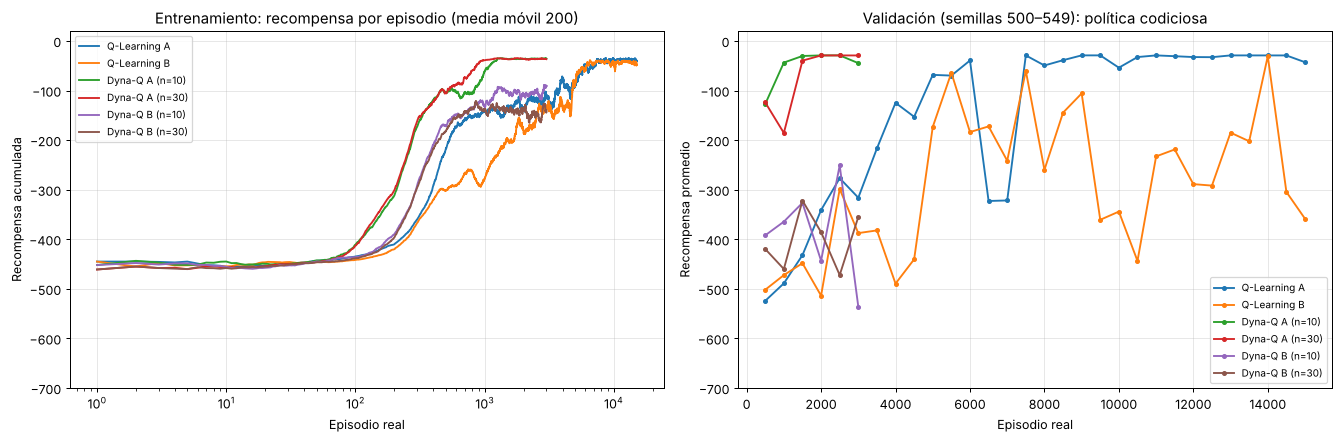

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for corrida, datos in historial_df.groupby('corrida', sort=False):
    ejes[0].plot(datos['episodio'], datos['recompensa'].rolling(200, min_periods=1).mean(), label=corrida)
ejes[0].set(title='Entrenamiento: recompensa por episodio (media móvil 200)', xlabel='Episodio real',
            ylabel='Recompensa acumulada', xscale='log', ylim=(-700, 20))
ejes[0].grid(alpha=0.3); ejes[0].legend(fontsize=8)

for corrida, datos in curvas_df.groupby('corrida', sort=False):
    ejes[1].plot(datos['episodio'], datos['val_recompensa_promedio'], marker='o', markersize=3, label=corrida)
ejes[1].set(title='Validación (semillas 500–549): política codiciosa', xlabel='Episodio real',
            ylabel='Recompensa promedio', ylim=(-700, 20))
ejes[1].grid(alpha=0.3); ejes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTADOS / 'qlearning_dynaq_curvas.png', dpi=150)
plt.show()

In [6]:
# Velocidad de aprendizaje: validación al mismo número de episodios reales.
comparacion_velocidad = (curvas_df[curvas_df['episodio'].isin([500, 1000, 2000, 3000, 15000])]
    .pivot_table(index='corrida', columns='episodio', values='val_recompensa_promedio', sort=False)
    .round(1))
comparacion_velocidad.columns = [f'val. a {c} ep.' for c in comparacion_velocidad.columns]
comparacion_velocidad

,val. a 500 ep.,val. a 1000 ep.,val. a 2000 ep.,val. a 3000 ep.,val. a 15000 ep.
corrida,,,,,
Q-Learning A,-524.2,-489.0,-341.2,-316.2,-42.9
Q-Learning B,-501.8,-472.3,-513.8,-387.6,-358.6
Dyna-Q A (n=10),-127.2,-43.6,-29.2,-44.8,NaN
Dyna-Q A (n=30),-124.0,-185.6,-29.3,-29.3,NaN
Dyna-Q B (n=10),-392.1,-364.5,-443.3,-536.0,NaN
Dyna-Q B (n=30),-419.7,-460.0,-385.7,-355.0,NaN


## 4. Selección por validación

Para cada algoritmo se elige la corrida con mayor recompensa promedio en la última validación (semillas 500–549). En caso de empate se elige la de mayor tasa de éxito. Las semillas 1000–1049 no participan en esta decisión.

In [7]:
ultima = curvas_df.sort_values('episodio').groupby('corrida').tail(1).set_index('corrida')
ultima = ultima.loc[[nombre_corrida(*e) for e in EXPERIMENTOS]]   # orden de los experimentos
seleccion = {}
for algoritmo in ['Q-Learning', 'Dyna-Q']:
    candidatos = ultima[ultima['algoritmo'] == algoritmo]
    seleccion[algoritmo] = candidatos.sort_values(['val_recompensa_promedio', 'val_tasa_exito_prendas'],
                                                  ascending=False).index[0]

tabla_seleccion = ultima[['algoritmo', 'configuracion', 'pasos_planificacion', 'episodio', 'segundos',
                          'val_recompensa_promedio', 'val_tasa_exito_prendas', 'val_pasos_promedio',
                          'val_acciones_invalidas_promedio']].copy()
tabla_seleccion['seleccionada'] = tabla_seleccion.index.isin(seleccion.values())
print('Seleccionadas:', seleccion)
tabla_seleccion.round(3)

Seleccionadas: {'Q-Learning': 'Q-Learning A', 'Dyna-Q': 'Dyna-Q A (n=30)'}


,algoritmo,configuracion,pasos_planificacion,episodio,segundos,val_recompensa_promedio,val_tasa_exito_prendas,val_pasos_promedio,val_acciones_invalidas_promedio,seleccionada
corrida,,,,,,,,,,
Q-Learning A,Q-Learning,A,0,15000,23.388,-42.88,0.884,90.66,0.00,True
Q-Learning B,Q-Learning,B,0,15000,25.741,-358.58,0.496,225.00,160.18,False
Dyna-Q A (n=10),Dyna-Q,A,10,3000,19.501,-44.76,0.880,92.40,0.00,False
Dyna-Q A (n=30),Dyna-Q,A,30,3000,41.536,-29.26,0.908,78.28,0.00,True
Dyna-Q B (n=10),Dyna-Q,B,10,3000,28.948,-536.04,0.128,290.72,252.04,False
Dyna-Q B (n=30),Dyna-Q,B,30,3000,76.038,-355.04,0.276,282.74,87.40,False


In [8]:
# Guardado de las tablas Q seleccionadas (forma 1408 x 6) con sus metadatos.
ARCHIVOS_Q = {'Q-Learning': MODELOS / 'q_table_qlearning.npz', 'Dyna-Q': MODELOS / 'q_table_dynaq.npz'}

if ENTRENAR:
    for algoritmo, corrida in seleccion.items():
        fila = ultima.loc[corrida]
        guardar_tabla_q(
            ARCHIVOS_Q[algoritmo], agentes[corrida], corrida=corrida, configuracion=fila['configuracion'],
            episodios_entrenamiento=int(fila['episodio']), tiempo_entrenamiento_s=round(float(fila['segundos']), 2),
            validacion_semillas='500-549', validacion_recompensa=round(float(fila['val_recompensa_promedio']), 3),
            validacion_tasa_exito=round(float(fila['val_tasa_exito_prendas']), 4),
            entorno=dict(prendas_por_episodio=PRENDAS_POR_EPISODIO, capacidad=CAPACIDAD_ESTANTE,
                         prob_estante_lleno=PROB_ESTANTE_LLENO, max_pasos=MAX_PASOS),
            protocolo=protocolo['version'], responsable='Luis Ángel Mendoza Gaytán',
        )

tablas_q = {}
for algoritmo, ruta in ARCHIVOS_Q.items():
    tabla, meta = cargar_tabla_q(ruta)
    tablas_q[algoritmo] = tabla
    print(f"{ruta} -> forma {tabla.shape}, {meta['corrida']}, alpha={meta['alpha']}, gamma={meta['gamma']}, "
          f"planeación={meta['pasos_planificacion']}, {meta['episodios_entrenamiento']} episodios, "
          f"{meta['tiempo_entrenamiento_s']} s")
    print(f"   estados visitados (alguna Q distinta de 0): {(np.abs(tabla).sum(axis=1) > 0).sum()} de {tabla.shape[0]}")

modelos/entrega3/q_table_qlearning.npz -> forma (1408, 6), Q-Learning A, alpha=0.1, gamma=0.95, planeación=0, 15000 episodios, 23.39 s
   estados visitados (alguna Q distinta de 0): 1176 de 1408
modelos/entrega3/q_table_dynaq.npz -> forma (1408, 6), Dyna-Q A (n=30), alpha=0.1, gamma=0.95, planeación=30, 3000 episodios, 41.54 s
   estados visitados (alguna Q distinta de 0): 1174 de 1408


In [9]:
# Configuraciones probadas: llena la plantilla configuraciones_hiperparametros.csv preparada por Ángel.
# Las métricas de esta tabla son de VALIDACIÓN (semillas 500-549), que es lo que se usó para elegir.
filas = []
for corrida, fila in ultima.iterrows():
    params = CONFIGURACIONES[fila['configuracion']]
    filas.append({
        'algoritmo': fila['algoritmo'], 'configuracion': fila['configuracion'],
        'alpha': params['alpha'], 'gamma': params['gamma'], 'epsilon_inicial': params['epsilon'],
        'epsilon_minimo': params['epsilon_min'], 'decaimiento_epsilon': params['epsilon_decay'],
        'pasos_planificacion': int(fila['pasos_planificacion']), 'episodios_entrenamiento': int(fila['episodio']),
        'recompensa_promedio': round(float(fila['val_recompensa_promedio']), 3),
        'tasa_exito_prendas': round(float(fila['val_tasa_exito_prendas']), 4),
        'pasos_promedio': round(float(fila['val_pasos_promedio']), 2),
        'semilla': SEMILLA, 'responsable': 'Luis Ángel Mendoza Gaytán',
        'estado': 'seleccionada' if corrida in seleccion.values() else 'completo',
    })
configuraciones_df = pd.DataFrame(filas)
configuraciones_df.to_csv(RESULTADOS / 'configuraciones_hiperparametros.csv', index=False)
configuraciones_df

,algoritmo,configuracion,alpha,gamma,epsilon_inicial,epsilon_minimo,decaimiento_epsilon,pasos_planificacion,episodios_entrenamiento,recompensa_promedio,tasa_exito_prendas,pasos_promedio,semilla,responsable,estado
0,Q-Learning,A,0.1,0.95,1.0,0.05,0.995,0,15000,-42.88,0.884,90.66,42,Luis Ángel Mendoza Gaytán,seleccionada
1,Q-Learning,B,0.2,0.99,1.0,0.05,0.997,0,15000,-358.58,0.496,225.00,42,Luis Ángel Mendoza Gaytán,completo
2,Dyna-Q,A,0.1,0.95,1.0,0.05,0.995,10,3000,-44.76,0.880,92.40,42,Luis Ángel Mendoza Gaytán,completo
3,Dyna-Q,A,0.1,0.95,1.0,0.05,0.995,30,3000,-29.26,0.908,78.28,42,Luis Ángel Mendoza Gaytán,seleccionada
4,Dyna-Q,B,0.2,0.99,1.0,0.05,0.997,10,3000,-536.04,0.128,290.72,42,Luis Ángel Mendoza Gaytán,completo
5,Dyna-Q,B,0.2,0.99,1.0,0.05,0.997,30,3000,-355.04,0.276,282.74,42,Luis Ángel Mendoza Gaytán,completo


## 5. Evaluación final en las semillas comunes 1000–1049

Se usan los mismos 50 episodios y los mismos parámetros del entorno que `03_evaluacion_rl.ipynb`. No hay exploración, la tabla Q no se actualiza y los empates se rompen con `np.random.default_rng(semilla)`. El agente aleatorio se vuelve a calcular aquí para comprobar que los episodios coinciden con los de Ángel.

In [10]:
politicas = {
    'Q-Learning': politica_tabla_q(tablas_q['Q-Learning']),
    'Dyna-Q': politica_tabla_q(tablas_q['Dyna-Q']),
    'Aleatorio': politica_aleatoria,
}
filas_eval, resumen = [], []
tiempo_por_algoritmo = {'Q-Learning': float(ultima.loc[seleccion['Q-Learning'], 'segundos']),
                        'Dyna-Q': float(ultima.loc[seleccion['Dyna-Q'], 'segundos']), 'Aleatorio': 0.0}
episodios_por_algoritmo = {'Q-Learning': int(ultima.loc[seleccion['Q-Learning'], 'episodio']),
                           'Dyna-Q': int(ultima.loc[seleccion['Dyna-Q'], 'episodio']), 'Aleatorio': 0}
for nombre, politica in politicas.items():
    episodios = evaluar_politica(crear_entorno, politica, SEMILLAS_EVALUACION)
    filas_eval += [dict(agente=nombre, **e) for e in episodios]
    resumen.append({**resumir(episodios), 'pasos_por_prenda': np.mean([e['pasos_por_prenda'] for e in episodios]),
                    'episodios_truncados': int(sum(e['truncado'] for e in episodios)),
                    'episodios_entrenamiento': episodios_por_algoritmo[nombre],
                    'tiempo_entrenamiento_s': round(tiempo_por_algoritmo[nombre], 2),
                    'configuracion': seleccion.get(nombre, '-'), 'agente': nombre, 'estado': 'completo'})

evaluacion_df = pd.DataFrame(filas_eval)
resumen_df = pd.DataFrame(resumen)
evaluacion_df.to_csv(RESULTADOS / 'qlearning_dynaq_evaluacion_episodios.csv', index=False)
resumen_df.round(4).to_csv(RESULTADOS / 'qlearning_dynaq_resumen.csv', index=False)
resumen_df.set_index('agente').round(3).T

agente,Q-Learning,Dyna-Q,Aleatorio
episodios,50,50,50
recompensa_promedio,-40.46,-27.8,-454.22
recompensa_desv,47.908,6.567,11.355
tasa_exito_prendas,0.924,0.936,0.016
tasa_exito_episodios,0.76,0.76,0.0
pasos_promedio,90.72,78.64,300.0
incorrectas_promedio,0.0,0.0,0.54
fallos_cnn_promedio,0.0,0.0,0.0
fallos_politica_promedio,0.0,0.0,0.54
acciones_invalidas_promedio,0.0,0.0,150.92


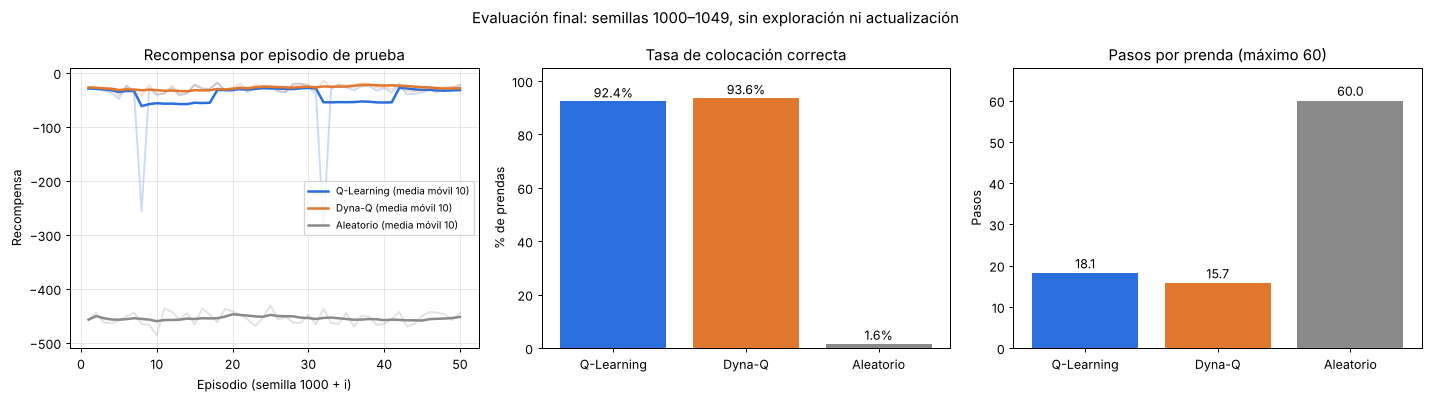

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
colores = {'Q-Learning': '#2a6fdb', 'Dyna-Q': '#e0782f', 'Aleatorio': '#8a8a8a'}
for nombre, datos in evaluacion_df.groupby('agente', sort=False):
    x = np.arange(1, len(datos) + 1)
    ejes[0].plot(x, datos['recompensa_total'], alpha=0.25, color=colores[nombre])
    ejes[0].plot(x, datos['recompensa_total'].rolling(10, min_periods=1).mean(), linewidth=2,
                 color=colores[nombre], label=f'{nombre} (media móvil 10)')
ejes[0].set(title='Recompensa por episodio de prueba', xlabel='Episodio (semilla 1000 + i)', ylabel='Recompensa')
ejes[0].grid(alpha=0.3); ejes[0].legend(fontsize=8)

r = resumen_df.set_index('agente')
ejes[1].bar(r.index, r['tasa_exito_prendas'] * 100, color=[colores[a] for a in r.index])
ejes[1].set(title='Tasa de colocación correcta', ylabel='% de prendas', ylim=(0, 105))
for i, v in enumerate(r['tasa_exito_prendas'] * 100):
    ejes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center')

ejes[2].bar(r.index, r['pasos_por_prenda'], color=[colores[a] for a in r.index])
ejes[2].set(title='Pasos por prenda (máximo 60)', ylabel='Pasos', ylim=(0, 68))
for i, v in enumerate(r['pasos_por_prenda']):
    ejes[2].text(i, v + 1.2, f'{v:.1f}', ha='center')
fig.suptitle('Evaluación final: semillas 1000–1049, sin exploración ni actualización')
fig.tight_layout()
fig.savefig(RESULTADOS / 'qlearning_dynaq_comparacion.png', dpi=150)
plt.show()

## 6. Simulación de 50 prendas con la CNN congelada

Se usan las predicciones de Juan José (`datos/entrega3/predicciones_50_prendas.csv`, generadas por `modelos/stylebot_cnn_final.keras` sin reentrenar). El agente solo ve la categoría **predicha**. La etiqueta real sirve únicamente para contar si una colocación fue correcta y para separar los fallos de la CNN de los fallos de la política. Se usa la misma configuración del entorno que `02_integracion_cnn_rl.ipynb`: semilla 2026, las 50 prendas en orden, capacidad 8 y 60 pasos por prenda.

In [12]:
predicciones_50 = pd.read_csv('datos/entrega3/predicciones_50_prendas.csv')
etiquetas_50 = predicciones_50['etiqueta_real'].to_numpy()
pred_50 = predicciones_50['prediccion'].to_numpy()
print('Prendas:', len(predicciones_50), '| errores de la CNN en las 50:', int(predicciones_50['es_error'].sum()))

def crear_entorno_50():
    return AlmacenStyleBot(etiquetas=etiquetas_50, predicciones=pred_50, prendas_por_episodio=len(etiquetas_50),
                           capacidad=CAPACIDAD_ESTANTE, max_pasos=len(etiquetas_50) * protocolo['max_pasos_por_prenda'],
                           recompensas=protocolo['recompensas'])

opciones_50 = {'indices': np.arange(len(etiquetas_50))}
filas_50, trayectorias = [], {}
for nombre, politica in politicas.items():
    fila, trayectoria = ejecutar_episodio(crear_entorno_50(), politica, SEMILLA_DEMO, opciones=opciones_50,
                                          guardar_trayectoria=True)
    filas_50.append({'agente': nombre, **fila})
    trayectorias[nombre] = pd.DataFrame(trayectoria)

simulacion_50 = pd.DataFrame(filas_50)
simulacion_50.to_csv(RESULTADOS / 'simulacion_50_prendas_rl.csv', index=False)
mejor_demo = 'Dyna-Q' if simulacion_50.set_index('agente').loc['Dyna-Q', 'recompensa_total'] >= \
    simulacion_50.set_index('agente').loc['Q-Learning', 'recompensa_total'] else 'Q-Learning'
trayectorias[mejor_demo].to_csv(RESULTADOS / 'trayectoria_50_prendas_rl.csv', index=False)
print('Trayectoria guardada para la demo:', mejor_demo)
simulacion_50.set_index('agente')[['recompensa_total', 'correctas', 'incorrectas', 'fallos_cnn', 'fallos_politica',
                                   'pasos', 'pasos_por_prenda', 'acciones_invalidas', 'intentos_estante_lleno',
                                   'devueltas', 'terminado', 'truncado']]

Prendas: 50 | errores de la CNN en las 50: 1
Trayectoria guardada para la demo: Dyna-Q


,recompensa_total,correctas,incorrectas,fallos_cnn,fallos_politica,pasos,pasos_por_prenda,acciones_invalidas,intentos_estante_lleno,devueltas,terminado,truncado
agente,,,,,,,,,,,,
Q-Learning,-413.0,49,1,1,0,945,18.90,0,0,0,True,False
Dyna-Q,-389.0,49,1,1,0,921,18.42,0,0,0,True,False
Aleatorio,-4502.0,1,5,0,5,3000,60.00,1478,0,0,False,True


In [13]:
# Detalle de la prenda mal clasificada por la CNN: el agente la lleva al estante de la categoría predicha.
errores = predicciones_50[predicciones_50['es_error']]
errores[['id_prenda', 'categoria_real', 'categoria_predicha', 'confianza', 'estante_real', 'estante_objetivo']]

,id_prenda,categoria_real,categoria_predicha,confianza,estante_real,estante_objetivo
34,34,Suéter,Camiseta/top,0.68887,"(0, 2)","(0, 0)"


## 7. Análisis

Las conclusiones se generan con los números de este notebook (celda siguiente). Puntos que se interpretan:

- **Velocidad de aprendizaje:** Dyna-Q aprovecha más cada episodio real, porque cada paso real también genera 10 o 30 actualizaciones con el modelo. Por eso alcanza buenas políticas con menos episodios, aunque cada episodio tarda más en tiempo de cómputo.
- **Oscilación de la validación de Q-Learning:** entre 5 000 y 15 000 episodios la validación sube y baja porque algunos estados poco visitados cambian de acción preferida. Se usa la tabla del último episodio, sin escoger el mejor punto intermedio.
- **Configuración A frente a B:** con el mismo presupuesto, B (α = 0.20, γ = 0.99, decaimiento más lento) queda con estados poco aprendidos. En ellos la política codiciosa repite acciones inválidas hasta el truncamiento a 300 pasos. Con γ = 0.99, el valor de un bucle de acciones inválidas baja muy despacio hacia −2/(1−γ) = −200, así que tarda mucho más en penalizarse que con γ = 0.95 (−40). Por eso la validación elige A.
- **Fallos de la CNN y de la política:** con percepción perfecta (semillas 1000–1049) todos los errores son de la política. En las 50 prendas, la CNN se equivoca en una prenda y el agente la lleva al estante de la categoría predicha, así que cuenta como fallo de la CNN y no de la política.
- **Estantes llenos:** cuando el estante destino está lleno (10 % al inicio), lo correcto es devolver la prenda en recepción (−3). Por eso la tasa máxima posible es menor que 100 %.

In [14]:
r = resumen_df.set_index('agente')
s = simulacion_50.set_index('agente')
v = comparacion_velocidad
print('Selección por validación:', seleccion)
print(f"Prueba 1000-1049 | Q-Learning: recompensa {r.loc['Q-Learning','recompensa_promedio']:.2f}, "
      f"éxito {r.loc['Q-Learning','tasa_exito_prendas']:.1%}, {r.loc['Q-Learning','pasos_por_prenda']:.1f} pasos/prenda, "
      f"{r.loc['Q-Learning','tiempo_entrenamiento_s']:.0f} s de entrenamiento")
print(f"Prueba 1000-1049 | Dyna-Q:     recompensa {r.loc['Dyna-Q','recompensa_promedio']:.2f}, "
      f"éxito {r.loc['Dyna-Q','tasa_exito_prendas']:.1%}, {r.loc['Dyna-Q','pasos_por_prenda']:.1f} pasos/prenda, "
      f"{r.loc['Dyna-Q','tiempo_entrenamiento_s']:.0f} s de entrenamiento")
print(f"Prueba 1000-1049 | Aleatorio:  recompensa {r.loc['Aleatorio','recompensa_promedio']:.2f}, "
      f"éxito {r.loc['Aleatorio','tasa_exito_prendas']:.1%}")
col = 'val. a 3000 ep.'
print(f"A 3000 episodios reales (validación): Q-Learning A {v.loc['Q-Learning A', col]:.1f} vs "
      f"Dyna-Q A n=10 {v.loc['Dyna-Q A (n=10)', col]:.1f} y n=30 {v.loc['Dyna-Q A (n=30)', col]:.1f}")
for agente in ['Q-Learning', 'Dyna-Q', 'Aleatorio']:
    print(f"50 prendas CNN | {agente:<10}: {int(s.loc[agente,'correctas'])}/50 correctas, "
          f"fallos CNN {int(s.loc[agente,'fallos_cnn'])}, fallos política {int(s.loc[agente,'fallos_politica'])}, "
          f"{int(s.loc[agente,'pasos'])} pasos, recompensa {s.loc[agente,'recompensa_total']:.0f}")

Selección por validación: {'Q-Learning': 'Q-Learning A', 'Dyna-Q': 'Dyna-Q A (n=30)'}
Prueba 1000-1049 | Q-Learning: recompensa -40.46, éxito 92.4%, 18.1 pasos/prenda, 23 s de entrenamiento
Prueba 1000-1049 | Dyna-Q:     recompensa -27.80, éxito 93.6%, 15.7 pasos/prenda, 42 s de entrenamiento
Prueba 1000-1049 | Aleatorio:  recompensa -454.22, éxito 1.6%
A 3000 episodios reales (validación): Q-Learning A -316.2 vs Dyna-Q A n=10 -44.8 y n=30 -29.3
50 prendas CNN | Q-Learning: 49/50 correctas, fallos CNN 1, fallos política 0, 945 pasos, recompensa -413
50 prendas CNN | Dyna-Q    : 49/50 correctas, fallos CNN 1, fallos política 0, 921 pasos, recompensa -389
50 prendas CNN | Aleatorio : 1/50 correctas, fallos CNN 0, fallos política 5, 3000 pasos, recompensa -4502


## 8. Archivos generados

| Archivo | Contenido | Lo usa |
|---|---|---|
| `modelos/entrega3/q_table_qlearning.npz` | Tabla Q (1408×6, clave `q_table`) y metadatos de la configuración elegida | Ángel, Jacqueline |
| `modelos/entrega3/q_table_dynaq.npz` | Tabla Q de Dyna-Q y metadatos | Ángel, Jacqueline |
| `resultados/entrega3/configuraciones_hiperparametros.csv` | Las 6 corridas con métricas de validación y la seleccionada | Ángel, informe |
| `resultados/entrega3/qlearning_dynaq_resumen.csv` | Métricas en las semillas 1000–1049 (mismas columnas que `comparacion_agentes.csv` más tiempo y pasos por prenda) | Ángel |
| `resultados/entrega3/qlearning_dynaq_evaluacion_episodios.csv` | Un renglón por episodio de prueba y agente | Ángel |
| `resultados/entrega3/qlearning_dynaq_historial_entrenamiento.csv` | Recompensa, pasos, ε y tiempo por episodio de entrenamiento | Ángel, informe |
| `resultados/entrega3/qlearning_dynaq_validacion.csv` | Curvas de validación cada 500 episodios | Informe |
| `resultados/entrega3/qlearning_dynaq_curvas.png`, `qlearning_dynaq_comparacion.png` | Gráficas | Informe |
| `resultados/entrega3/simulacion_50_prendas_rl.csv`, `trayectoria_50_prendas_rl.csv` | Simulación de 50 prendas con la CNN y su trayectoria paso a paso | Jacqueline (demo) |

Para usar una tabla Q en otro notebook:

```python
from src.entrega3.agentes_rl import cargar_tabla_q, politica_tabla_q
tabla_q, meta = cargar_tabla_q('modelos/entrega3/q_table_dynaq.npz')
politica = politica_tabla_q(tabla_q)   # firma (estado, entorno, rng) -> acción, igual que en 03_evaluacion_rl
```